# Part B: Digital Twin of the Hospital (SimPy)

Uses `hospital.duckdb` (synthetic Synthea cohort + risk scores from A).

**Goal:** a function `simulate(config) -> DataFrame` (one row per replication) that the dashboard can call.

**Order of work:** load data → historical occupancy → arrival process → length of stay → SimPy model → validation → experiments → sensitivity → cost.

> **Assumptions to copy into `docs/ASSUMPTIONS.md`:** scale-up factor, intervention effectiveness, cost per bed-day, returning patients get a fresh random (risk, LOS) draw, loss system (no queue).

## 0. Setup

In [1]:
!pip -q install duckdb simpy scipy


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\AKSHAYA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import sys

!{sys.executable} -m pip install duckdb simpy scipy pandas numpy matplotlib

  Using cached duckdb-2.0.0-cp312-abi3-win_amd64.whl.metadata (4.1 kB)
  Using cached simpy-4.1.2-py3-none-any.whl.metadata (6.2 kB)
Using cached duckdb-2.0.0-cp312-abi3-win_amd64.whl (15.4 MB)
Using cached simpy-4.1.2-py3-none-any.whl (27 kB)

   ---------------------------------------- 0/2 [simpy]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   -------------------- ------------------- 1/2 [duckdb]
   ------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import duckdb
import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import duckdb, simpy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 160)

# Put hospital.duckdb in the same folder as this notebook.
DB = Path('hospital.duckdb')
if not DB.exists():
    raise FileNotFoundError(
        f'Could not find {DB.resolve()}\n'
        'Copy hospital.duckdb into the same folder as this notebook, then rerun this cell.'
    )

con = duckdb.connect(str(DB), read_only=True)
con.execute("SET TimeZone='UTC'")
tables = {row[0] for row in con.execute('SHOW TABLES').fetchall()}
print('Database:', DB.resolve())
print('Tables:', sorted(tables))

required = {'syn_stays', 'syn_risk_scores'}
missing = required - tables
if missing:
    raise ValueError(
        f'This database is missing required table(s): {sorted(missing)}. '
        f'Available tables: {sorted(tables)}. Use the hospital.duckdb created for Part A.'
    )

print('syn_stays rows:', con.execute('SELECT COUNT(*) FROM syn_stays').fetchone()[0])
print('syn_risk_scores rows:', con.execute('SELECT COUNT(*) FROM syn_risk_scores').fetchone()[0])


Database: C:\Users\AKSHAYA\OneDrive\Desktop\Hospital_Digital_Twin\hospital.duckdb
Tables: ['syn_allergies', 'syn_careplans', 'syn_claims', 'syn_claims_transactions', 'syn_conditions', 'syn_devices', 'syn_encounters', 'syn_features', 'syn_imaging_studies', 'syn_immunizations', 'syn_medications', 'syn_observations', 'syn_organizations', 'syn_patients', 'syn_payer_transitions', 'syn_payers', 'syn_procedures', 'syn_providers', 'syn_risk_scores', 'syn_stays', 'syn_supplies', 'uci_clean', 'uci_diabetes']
syn_stays rows: 2023
syn_risk_scores rows: 2023


## 1. Load the cohort and risk scores

In [6]:
stays  = con.execute("SELECT * FROM syn_stays").df()
scores = con.execute("SELECT PATIENT, START, STOP, los_days, age, GENDER, RACE, readmit_30d, risk_lr, risk_gb, lace FROM syn_risk_scores").df()

for d in (stays, scores):
    d["START"] = pd.to_datetime(d["START"], utc=True)
    d["STOP"]  = pd.to_datetime(d["STOP"],  utc=True)

print(stays.shape, scores.shape)
print("Readmission rate:", stays["readmit_30d"].mean().round(3))
scores[["los_days", "risk_lr"]].describe()

(2023, 10) (2023, 11)
Readmission rate: 0.126


,los_days,risk_lr
count,2023.000000,2023.000000
mean,5.798921,0.117980
std,5.345199,0.143800
min,1.000000,0.000360
25%,2.033166,0.021317
50%,4.388194,0.034917
75%,7.769444,0.260397
max,49.963611,0.824526


## 2. Historical occupancy (for validation)

Two definitions:
- **overlap**: any stay touching that calendar day (the SQL in the guide)
- **snapshot**: patients in a bed at midnight (this is what the simulation monitor measures, so **use this one to validate**)

       overlap  snapshot
count  3287.00   3287.00
mean      4.19      3.57
std       2.28      2.12
min       0.00      0.00
25%       3.00      2.00
50%       4.00      3.00
75%       5.00      5.00
max      17.00     15.00
snapshot p95: 7.0


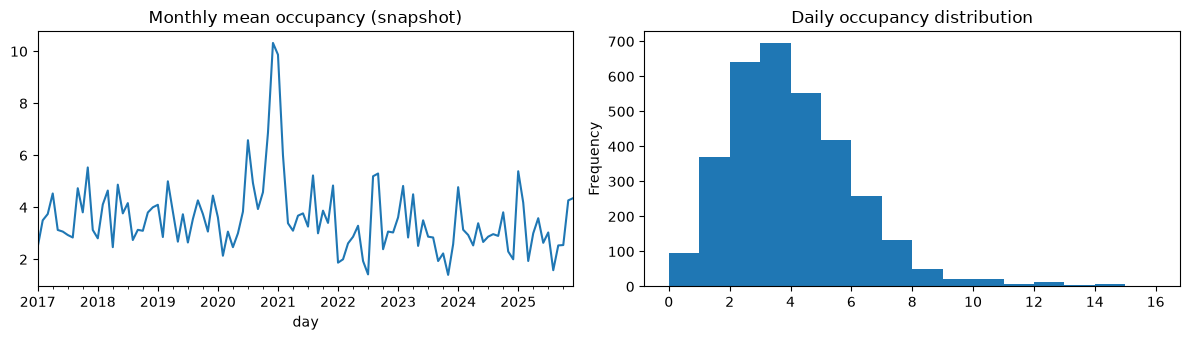

In [7]:
occ_sql = '''
SELECT CAST(d AS DATE) AS day,
       COUNT(s.PATIENT) FILTER (WHERE CAST(s.START AS TIMESTAMP) <  d + INTERVAL 1 DAY
                                  AND CAST(s.STOP  AS TIMESTAMP) >  d)  AS overlap,
       COUNT(s.PATIENT) FILTER (WHERE CAST(s.START AS TIMESTAMP) <= d
                                  AND CAST(s.STOP  AS TIMESTAMP) >  d)  AS snapshot
FROM generate_series(TIMESTAMP '2017-01-01', TIMESTAMP '2025-12-31', INTERVAL 1 DAY) t(d)
LEFT JOIN syn_stays s
  ON CAST(s.START AS TIMESTAMP) < d + INTERVAL 1 DAY AND CAST(s.STOP AS TIMESTAMP) > d
GROUP BY 1 ORDER BY 1
'''
hist = con.execute(occ_sql).df()
hist["day"] = pd.to_datetime(hist["day"])

print(hist[["overlap", "snapshot"]].describe().round(2))
print("snapshot p95:", hist["snapshot"].quantile(0.95))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
hist.set_index("day")["snapshot"].resample("MS").mean().plot(ax=ax[0], title="Monthly mean occupancy (snapshot)")
hist["snapshot"].plot.hist(bins=range(0, int(hist["snapshot"].max()) + 2), ax=ax[1], title="Daily occupancy distribution")
plt.tight_layout(); plt.show()

## 3. Arrival process (new admissions only)

Readmissions are generated by the simulation, so the arrival rate is fitted on **new** admissions only (a stay that starts 0 to 30 days after the previous discharge is a readmission).

In [8]:
s = stays.sort_values(["PATIENT", "START"]).copy()
prev_stop = s.groupby("PATIENT")["STOP"].shift(1)
s["gap_days"] = (s["START"] - prev_stop).dt.total_seconds() / 86400
s["is_readmission"] = s["gap_days"].between(0, 30)

new = s[~s["is_readmission"]]
readm = s[s["is_readmission"]]

N_DAYS_HIST = (pd.Timestamp("2025-12-31") - pd.Timestamp("2017-01-01")).days + 1
RATE = len(new) / N_DAYS_HIST
print(f"new admissions: {len(new)}, readmissions: {len(readm)}, total: {len(s)}")
print(f"rate of NEW admissions per day: {RATE:.3f}")

# Empirical readmission gaps (days from discharge to next admission)
GAPS = readm["gap_days"].to_numpy()
print("gap days: mean %.1f, min %.1f, max %.1f" % (GAPS.mean(), GAPS.min(), GAPS.max()))

new admissions: 1775, readmissions: 248, total: 2023
rate of NEW admissions per day: 0.540
gap days: mean 25.9, min 2.4, max 30.0


daily count: mean=0.540, var=0.546, var/mean=1.01  (Poisson ~ 1.0)
weekday chi-square p = 0.769
month   chi-square p = 0.062


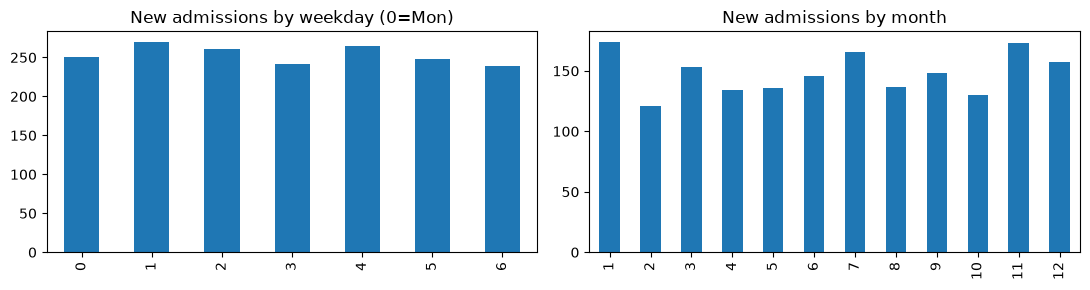

In [9]:
# Is a Poisson process reasonable? Check dispersion, weekday and month effects.
days = pd.date_range("2017-01-01", "2025-12-31", freq="D", tz="UTC")
daily = new.set_index(new["START"].dt.floor("D")).groupby(level=0).size().reindex(days, fill_value=0)

print(f"daily count: mean={daily.mean():.3f}, var={daily.var():.3f}, var/mean={daily.var()/daily.mean():.2f}  (Poisson ~ 1.0)")

wd = daily.groupby(daily.index.dayofweek).sum()
mo = daily.groupby(daily.index.month).sum()
# Expected counts under 'no effect' need to account for how many of each weekday / month exist
wd_exp = pd.Series(daily.index.dayofweek).value_counts().sort_index() / len(daily) * daily.sum()
mo_exp = pd.Series(daily.index.month).value_counts().sort_index() / len(daily) * daily.sum()
print("weekday chi-square p =", round(stats.chisquare(wd.values, wd_exp.values).pvalue, 3))
print("month   chi-square p =", round(stats.chisquare(mo.values, mo_exp.values).pvalue, 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
wd.plot.bar(ax=ax[0], title="New admissions by weekday (0=Mon)")
mo.plot.bar(ax=ax[1], title="New admissions by month")
plt.tight_layout(); plt.show()

**Decision (edit after you see the output):** if the dispersion is near 1 and the chi-square p-values are not small, use a homogeneous Poisson process at `RATE`. Otherwise mention the weekday/season effect as a limitation and keep the simple model.

## 4. Length of stay and risk

Bootstrap **rows** of `(los_days, risk_lr)` from `syn_risk_scores`, so long stays stay linked to risk and no distribution fit is needed.

LOS mean 5.80, median 4.39, p95 15.00
mean risk_lr 0.118  vs observed readmit rate 0.126
corr(LOS, risk): 0.121


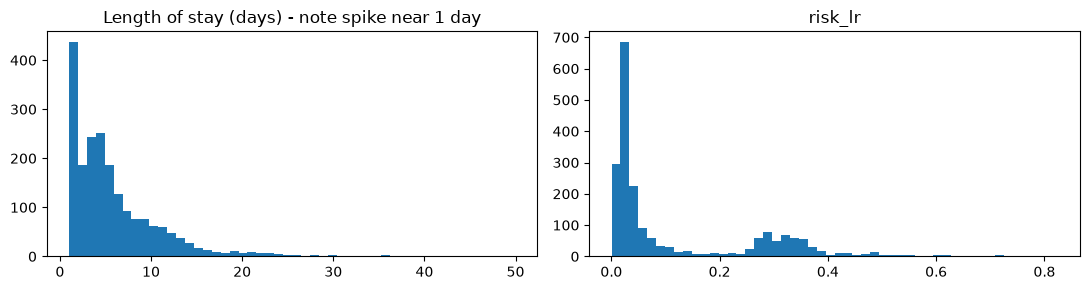

In [10]:
scores = scores.dropna(subset=["los_days", "risk_lr"]).reset_index(drop=True)
RISK    = scores["risk_lr"].to_numpy()
LOS     = scores["los_days"].to_numpy()
READMIT = scores["readmit_30d"].astype(bool).to_numpy()
RISK_SD = RISK.std()

print("LOS mean %.2f, median %.2f, p95 %.2f" % (LOS.mean(), np.median(LOS), np.quantile(LOS, .95)))
print("mean risk_lr %.3f  vs observed readmit rate %.3f" % (RISK.mean(), READMIT.mean()))
print("corr(LOS, risk):", np.corrcoef(LOS, RISK)[0, 1].round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(LOS, bins=50); ax[0].set_title("Length of stay (days) - note spike near 1 day")
ax[1].hist(RISK, bins=50); ax[1].set_title("risk_lr")
plt.tight_layout(); plt.show()

## 5. SimPy model

Design (state these in the report):
- Poisson arrivals of **new** patients; each draws a `(risk, los)` row.
- **Loss system:** if all beds are taken the patient is *blocked* (no queue).
- At discharge: the patient returns with probability `risk` (a readmission). If flagged by the policy (top `top_pct`% by score), probability becomes `risk * (1 - effectiveness)`.
- The same random number `u` decides both outcomes, so "prevented" = would have returned without the policy but did not with it.
- A returning patient comes back after an empirical gap and gets a **fresh** `(risk, los)` draw (simplification).
- Warm-up days are discarded. Occupancy is sampled once per day (midnight snapshot).
- `score_noise` (optional): makes targeting worse by adding noise to the score used for flagging (see section 8).

In [11]:
DEFAULTS = dict(beds=80, arrival_scale=1.0, top_pct=0, effectiveness=0.2,
                n_days=365, n_reps=30, seed=42,
                warmup_days=60, los_scale=1.0, score_noise=0.0, keep_occ=False)

def run_once(cfg, rng):
    env  = simpy.Environment()
    beds = simpy.Resource(env, capacity=int(cfg["beds"]))
    warm = cfg["warmup_days"]
    st = dict(blocked=0, readm=0, prevented=0, bed_days=0.0, occ=[])

    lam       = RATE * cfg["arrival_scale"]
    los_scale = cfg["los_scale"]
    sigma     = cfg["score_noise"] * RISK_SD
    eff       = cfg["effectiveness"]

    # flagging threshold (on the possibly noisy score)
    if cfg["top_pct"] > 0:
        score_all = RISK + rng.normal(0, sigma, len(RISK)) if sigma > 0 else RISK
        thr = np.quantile(score_all, 1 - cfg["top_pct"] / 100)
    else:
        thr = np.inf

    def patient(i):
        risk, los = RISK[i], LOS[i] * los_scale
        if beds.count >= beds.capacity:                 # loss system
            if env.now >= warm: st["blocked"] += 1
            return
        with beds.request() as req:
            yield req
            if env.now >= warm: st["bed_days"] += los
            yield env.timeout(los)

        score = risk + (rng.normal(0, sigma) if sigma > 0 else 0.0)
        p = risk * (1 - eff) if score >= thr else risk
        u = rng.random()                                # shared draw -> paired comparison
        if u < p:
            if env.now >= warm: st["readm"] += 1
            env.process(returner())
        elif u < risk:
            if env.now >= warm: st["prevented"] += 1

    def returner():
        yield env.timeout(rng.choice(GAPS))
        env.process(patient(rng.integers(len(RISK))))

    def arrivals():
        while True:
            yield env.timeout(rng.exponential(1 / lam))
            env.process(patient(rng.integers(len(RISK))))

    def monitor():
        while True:
            if env.now >= warm: st["occ"].append(beds.count)
            yield env.timeout(1)

    env.process(arrivals()); env.process(monitor())
    env.run(until=warm + cfg["n_days"])
    return st


def simulate(config=None, **overrides):
    """One row per replication. Columns: rep, mean_occupancy, max_occupancy, bed_days,
    blocked_admissions, readmissions, readmissions_prevented."""
    cfg = {**DEFAULTS, **(config or {}), **overrides}
    rows, occs = [], []
    for rep in range(int(cfg["n_reps"])):
        rng = np.random.default_rng([cfg["seed"], rep])     # same seeds across scenarios
        st = run_once(cfg, rng)
        occ = np.array(st["occ"])
        occs.append(occ)
        rows.append(dict(rep=rep, mean_occupancy=occ.mean(), max_occupancy=int(occ.max()),
                         bed_days=st["bed_days"], blocked_admissions=st["blocked"],
                         readmissions=st["readm"], readmissions_prevented=st["prevented"]))
    df = pd.DataFrame(rows)
    if cfg["keep_occ"]:
        df.attrs["occ"] = occs
    return df

# quick smoke test
simulate(n_reps=3, n_days=200, beds=1000)

,rep,mean_occupancy,max_occupancy,bed_days,blocked_admissions,readmissions,readmissions_prevented
0,0,2.930,9,579.786424,0,15,0
1,1,3.690,10,721.684965,0,13,0
2,2,3.505,10,695.039815,0,17,0


## 6. Validation (before any policy)

Unlimited beds, `arrival_scale = 1`, no policy. Compare the **distribution** of daily occupancy to the historical midnight snapshot (mean, SD, 95th percentile).

            mean   std  p95  max
historical  3.57  2.12  7.0   15
simulated   3.57  1.90  7.0   16
blocked (should be 0): 0


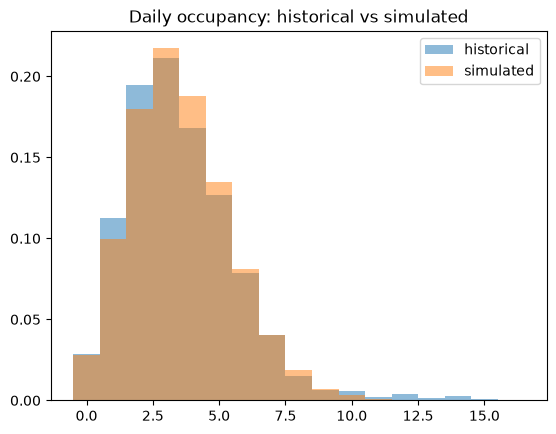

In [12]:
val = simulate(beds=10_000, arrival_scale=1.0, top_pct=0, n_days=3000, n_reps=10, keep_occ=True)
sim_occ = np.concatenate(val.attrs["occ"])
h = hist["snapshot"].to_numpy()

cmp = pd.DataFrame({
    "mean": [h.mean(), sim_occ.mean()],
    "std":  [h.std(),  sim_occ.std()],
    "p95":  [np.quantile(h, .95), np.quantile(sim_occ, .95)],
    "max":  [h.max(), sim_occ.max()],
}, index=["historical", "simulated"]).round(2)
print(cmp)
print("blocked (should be 0):", val["blocked_admissions"].sum())

bins = np.arange(0, max(h.max(), sim_occ.max()) + 2) - 0.5
plt.hist(h, bins=bins, alpha=.5, density=True, label="historical")
plt.hist(sim_occ, bins=bins, alpha=.5, density=True, label="simulated")
plt.legend(); plt.title("Daily occupancy: historical vs simulated"); plt.show()

**Acceptance check:** the simulated mean should be close to the historical mean (a few percent). If it is clearly off, look at: the readmission gap sampling, the fresh-row simplification for returners, and whether the historical window includes ramp-up years.

## 7. Policy experiments

`arrival_scale = 20` represents a hospital of roughly 70 to 80 beds (**scaling assumption**). At least 30 replications per scenario; mean with 95% CI. Differences vs. the baseline are **paired by replication** (same seeds).

In [13]:
SCALE = 20
BASE = dict(beds=80, arrival_scale=SCALE, effectiveness=0.2, n_days=365, n_reps=30, seed=42)

def ci95(x):
    x = np.asarray(x, float); n = len(x)
    m = x.mean(); h = stats.t.ppf(.975, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return m, m - h, m + h

COLS = ["mean_occupancy", "blocked_admissions", "readmissions", "readmissions_prevented", "bed_days"]

def run_scenarios(scenarios, base=BASE, baseline="no policy"):
    results = {name: simulate({**base, **ov}) for name, ov in scenarios.items()}
    rows = []
    for name, df in results.items():
        r = {"scenario": name}
        for c in COLS:
            m, lo, hi = ci95(df[c])
            r[c] = f"{m:,.1f} [{lo:,.1f}, {hi:,.1f}]"
        if baseline in results:
            for c in ["bed_days", "blocked_admissions", "readmissions"]:
                d = results[baseline][c].to_numpy() - df[c].to_numpy()     # positive = improvement vs baseline
                m, lo, hi = ci95(d)
                r[f"{c} saved vs base"] = f"{m:,.1f} [{lo:,.1f}, {hi:,.1f}]"
        rows.append(r)
    return pd.DataFrame(rows).set_index("scenario"), results

scenarios = {
    "no policy":          dict(top_pct=0),
    "top 5%":             dict(top_pct=5),
    "top 10%":            dict(top_pct=10),
    "top 20%":            dict(top_pct=20),
    "surge x1.2 (no policy)":   dict(top_pct=0, arrival_scale=SCALE * 1.2),
    "surge x1.2 + top 10%":     dict(top_pct=10, arrival_scale=SCALE * 1.2),
    "beds -10% (no policy)":    dict(top_pct=0, beds=72),
    "beds -10% + top 10%":      dict(top_pct=10, beds=72),
}
table_main, res_main = run_scenarios(scenarios)
table_main

,mean_occupancy,blocked_admissions,readmissions,readmissions_prevented,bed_days,bed_days saved vs base,blocked_admissions saved vs base,readmissions saved vs base
scenario,,,,,,,,
no policy,"68.5 [68.1, 68.9]","118.0 [103.8, 132.3]","508.1 [498.1, 518.1]","0.0 [0.0, 0.0]","24,969.0 [24,822.9, 25,115.2]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]"
top 5%,"68.6 [68.2, 69.0]","116.6 [104.6, 128.7]","494.2 [485.6, 502.8]","21.3 [19.8, 22.7]","25,058.9 [24,923.3, 25,194.4]","-89.8 [-259.9, 80.3]","1.4 [-16.0, 18.8]","13.9 [1.3, 26.5]"
top 10%,"68.4 [68.0, 68.7]","116.5 [105.8, 127.2]","471.8 [462.5, 481.2]","36.7 [34.8, 38.7]","24,981.0 [24,854.0, 25,107.9]","-11.9 [-172.5, 148.6]","1.5 [-9.0, 12.1]","36.2 [26.7, 45.7]"
top 20%,"67.8 [67.5, 68.2]","92.0 [81.4, 102.5]","446.7 [439.5, 453.8]","62.9 [60.8, 65.0]","24,748.0 [24,621.7, 24,874.4]","221.0 [57.0, 385.1]","26.1 [10.1, 42.0]","61.4 [49.2, 73.6]"
surge x1.2 (no policy),"74.4 [74.2, 74.6]","588.5 [566.7, 610.4]","560.0 [549.9, 570.1]","0.0 [0.0, 0.0]","27,147.0 [27,072.3, 27,221.6]","-2,177.9 [-2,311.2, -2,044.7]","-470.5 [-493.7, -447.3]","-51.9 [-64.3, -39.5]"
surge x1.2 + top 10%,"74.4 [74.2, 74.5]","572.0 [550.6, 593.5]","514.3 [506.0, 522.6]","39.4 [37.2, 41.7]","27,137.0 [27,066.8, 27,207.1]","-2,167.9 [-2,323.8, -2,012.0]","-454.0 [-476.2, -431.8]","-6.2 [-18.2, 5.8]"
beds -10% (no policy),"65.1 [64.9, 65.3]","334.5 [312.4, 356.5]","474.8 [467.4, 482.3]","0.0 [0.0, 0.0]","23,766.9 [23,684.6, 23,849.1]","1,202.2 [1,077.2, 1,327.1]","-216.4 [-236.4, -196.4]","33.2 [21.2, 45.3]"
beds -10% + top 10%,"64.8 [64.6, 65.0]","303.4 [283.2, 323.5]","447.8 [441.1, 454.6]","34.9 [32.5, 37.3]","23,669.8 [23,588.9, 23,750.6]","1,299.3 [1,142.0, 1,456.6]","-185.3 [-206.2, -164.5]","60.2 [49.1, 71.4]"


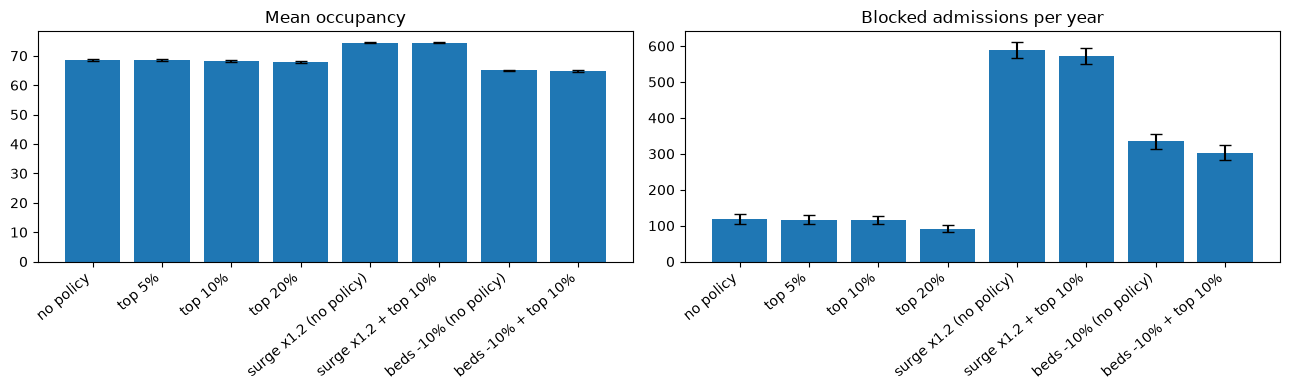

In [14]:
# Occupancy / blocking plot with 95% CI
names = list(res_main)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col, title in [(ax[0], "mean_occupancy", "Mean occupancy"), (ax[1], "blocked_admissions", "Blocked admissions per year")]:
    stats_ = [ci95(res_main[n][col]) for n in names]
    m = np.array([s[0] for s in stats_]); err = np.array([[s[0]-s[1] for s in stats_], [s[2]-s[0] for s in stats_]])
    a.bar(range(len(names)), m, yerr=err, capsize=4)
    a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=40, ha="right"); a.set_title(title)
plt.tight_layout(); plt.show()

## 8. Pessimistic targeting (UCI capture rates)

Real-data capture rates are lower than Synthea's. We add noise to the score used for flagging until the top-k capture matches the UCI figures (top 5/10/20/30% = 13.5 / 23.0 / 38.1 / 51.4%). The true risk still drives who actually returns.

In [15]:
UCI_CAPTURE = {5: .135, 10: .230, 20: .381, 30: .514}

def capture(sigma_mult, k, n_draws=30, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n_draws):
        score = RISK + rng.normal(0, sigma_mult * RISK_SD, len(RISK))
        idx = score >= np.quantile(score, 1 - k / 100)
        out.append(READMIT[idx].sum() / READMIT.sum())
    return np.mean(out)

grid = [0, 0.5, 1, 2, 3, 5, 8]
cal = pd.DataFrame({f"top {k}%": [capture(sg, k) for sg in grid] for k in UCI_CAPTURE}, index=pd.Index(grid, name="score_noise"))
print("Target (UCI):", UCI_CAPTURE)
cal.round(3)

Target (UCI): {5: 0.135, 10: 0.23, 20: 0.381, 30: 0.514}


,top 5%,top 10%,top 20%,top 30%
score_noise,,,,
0.0,0.149,0.286,0.541,0.773
0.5,0.131,0.273,0.535,0.734
1.0,0.126,0.257,0.464,0.616
2.0,0.103,0.198,0.353,0.476
3.0,0.085,0.164,0.301,0.419
5.0,0.071,0.135,0.262,0.371
8.0,0.064,0.120,0.237,0.346


In [16]:
# pick the noise level whose top-10% capture is closest to UCI's 23.0%
best = min(grid, key=lambda sg: abs(capture(sg, 10) - UCI_CAPTURE[10]))
print("chosen score_noise:", best)

table_uci, res_uci = run_scenarios({
    "no policy":                 dict(top_pct=0),
    "top 10% (Synthea targeting)": dict(top_pct=10),
    "top 10% (UCI-like targeting)": dict(top_pct=10, score_noise=best),
})
table_uci

chosen score_noise: 1


,mean_occupancy,blocked_admissions,readmissions,readmissions_prevented,bed_days,bed_days saved vs base,blocked_admissions saved vs base,readmissions saved vs base
scenario,,,,,,,,
no policy,"68.5 [68.1, 68.9]","118.0 [103.8, 132.3]","508.1 [498.1, 518.1]","0.0 [0.0, 0.0]","24,969.0 [24,822.9, 25,115.2]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","0.0 [0.0, 0.0]"
top 10% (Synthea targeting),"68.4 [68.0, 68.7]","116.5 [105.8, 127.2]","471.8 [462.5, 481.2]","36.7 [34.8, 38.7]","24,981.0 [24,854.0, 25,107.9]","-11.9 [-172.5, 148.6]","1.5 [-9.0, 12.1]","36.2 [26.7, 45.7]"
top 10% (UCI-like targeting),"68.6 [68.1, 69.0]","117.5 [105.7, 129.3]","474.7 [465.3, 484.2]","32.1 [30.1, 34.1]","25,018.7 [24,865.7, 25,171.8]","-49.7 [-243.1, 143.8]","0.5 [-18.0, 19.1]","33.3 [20.2, 46.5]"


## 9. Sensitivity analysis

Vary `effectiveness` (0.1, 0.2, 0.3), arrival rate (±20%) and length of stay (±20%), all with the top-10% policy compared against no policy under the *same* conditions. **If the conclusion flips, say so.**

In [17]:
def policy_effect(label, **ov):
    # paired: no policy vs top 10% under the same conditions
    off = simulate({**BASE, **ov, "top_pct": 0})
    on  = simulate({**BASE, **ov, "top_pct": 10})
    row = {"case": label}
    for c in ["bed_days", "blocked_admissions", "readmissions"]:
        m, lo, hi = ci95(off[c].to_numpy() - on[c].to_numpy())
        row[f"{c} saved"] = f"{m:,.1f} [{lo:,.1f}, {hi:,.1f}]"
        row[f"_{c}_sig"] = (lo > 0) or (hi < 0)
    return row

rows = []
for e in (0.1, 0.2, 0.3):
    rows.append(policy_effect(f"effectiveness={e}", effectiveness=e))
for f in (0.8, 1.2):
    rows.append(policy_effect(f"arrival x{f}", arrival_scale=SCALE * f))
for f in (0.8, 1.2):
    rows.append(policy_effect(f"LOS x{f}", los_scale=f))

sens = pd.DataFrame(rows).set_index("case")
sens[[c for c in sens.columns if not c.startswith("_")]]

,bed_days saved,blocked_admissions saved,readmissions saved
case,,,
effectiveness=0.1,"-197.7 [-371.3, -24.0]","-11.0 [-25.4, 3.5]","16.7 [6.1, 27.3]"
effectiveness=0.2,"-11.9 [-172.5, 148.6]","1.5 [-9.0, 12.1]","36.2 [26.7, 45.7]"
effectiveness=0.3,"121.8 [-32.8, 276.3]","12.8 [-0.3, 26.0]","57.7 [46.3, 69.1]"
arrival x0.8,"278.5 [90.0, 467.0]","1.3 [-1.6, 4.1]","33.9 [24.6, 43.2]"
arrival x1.2,"10.0 [-90.9, 110.9]","16.5 [-11.5, 44.5]","45.7 [31.7, 59.7]"
LOS x0.8,"155.3 [27.9, 282.7]","-1.4 [-3.3, 0.5]","41.1 [30.7, 51.5]"
LOS x1.2,"36.7 [-54.7, 128.1]","27.1 [-3.1, 57.2]","32.7 [21.5, 43.9]"


In [18]:
# Which cases show a statistically clear effect on bed-days (95% CI excludes 0)?
sens[["_bed_days_sig", "_blocked_admissions_sig", "_readmissions_sig"]]

,_bed_days_sig,_blocked_admissions_sig,_readmissions_sig
case,,,
effectiveness=0.1,True,False,True
effectiveness=0.2,False,False,True
effectiveness=0.3,False,False,True
arrival x0.8,True,False,True
arrival x1.2,False,False,True
LOS x0.8,True,False,True
LOS x1.2,False,False,True


## 10. Cost estimate (one stated assumption)

`COST_PER_BED_DAY` is an **assumption**, not a real hospital figure. Replace with whatever the team agrees on in `docs/ASSUMPTIONS.md`.

In [19]:
COST_PER_BED_DAY = 1000   # ASSUMPTION (currency units per bed-day)

saved = {}
for n in ["top 5%", "top 10%", "top 20%"]:
    d = (res_main["no policy"]["bed_days"] - res_main[n]["bed_days"]).to_numpy()
    m, lo, hi = ci95(d)
    saved[n] = dict(bed_days_saved=m, ci_low=lo, ci_high=hi,
                    money_saved=m * COST_PER_BED_DAY,
                    money_ci_low=lo * COST_PER_BED_DAY, money_ci_high=hi * COST_PER_BED_DAY)
pd.DataFrame(saved).T.round(0)

,bed_days_saved,ci_low,ci_high,money_saved,money_ci_low,money_ci_high
top 5%,-90.0,-260.0,80.0,-89829.0,-259919.0,80261.0
top 10%,-12.0,-172.0,149.0,-11917.0,-172476.0,148643.0
top 20%,221.0,57.0,385.0,221023.0,56986.0,385060.0


**Note:** the intervention itself costs money too (staff, follow-up calls). This estimate only counts bed-days; say so in the report, and don't present it as a net saving.

## 11. Save results

In [21]:
table_main.to_csv('sim_main_results.csv')
table_uci.to_csv('sim_uci_targeting.csv')
sens[[c for c in sens.columns if not c.startswith('_')]].to_csv('sim_sensitivity.csv')

print('Saved result files in:', Path.cwd())
print(' - sim_main_results.csv')
print(' - sim_uci_targeting.csv')
print(' - sim_sensitivity.csv')


Saved result files in: c:\Users\AKSHAYA\OneDrive\Desktop\Hospital_Digital_Twin
 - sim_main_results.csv
 - sim_uci_targeting.csv
 - sim_sensitivity.csv


## Notes for the report / next steps

- Move `DEFAULTS`, `run_once`, `simulate` plus the data-loading cell into `simulation/simulate.py` so C can `from simulation.simulate import simulate`. Agree the config keys with C: `beds, arrival_scale, top_pct, effectiveness, n_days, n_reps, seed` (the extra keys here have defaults).
- Limitations: Synthea is rule-generated; scale-up is an assumption; effectiveness is an assumption; returners get fresh random (risk, LOS); loss system ignores queuing; blocked patients' possible readmissions are not simulated.
- Checkpoint (week 6): a validated baseline = section 6 table close to the historical one.